<>:28: SyntaxWarning: invalid escape sequence '\d'
<>:28: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1077/2638542115.py:28: SyntaxWarning: invalid escape sequence '\d'
  ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):


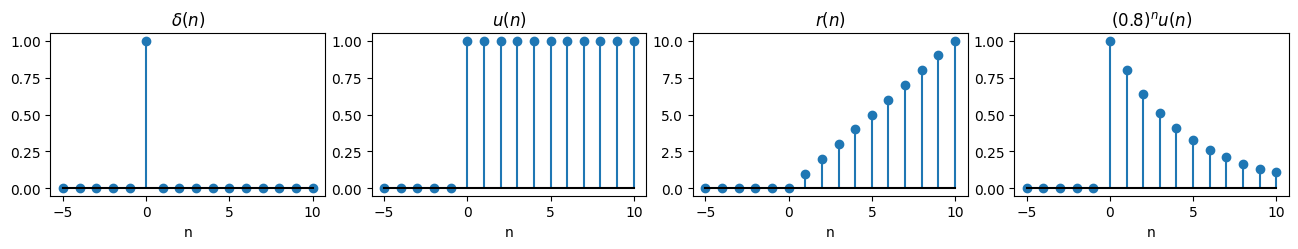

In [ ]:
# =====================================================================
# MODULE: DIGITAL SIGNAL PROCESSING (COU 07506)
# LAB 0: Setting Up the DSP Laboratory
# STUDENT: ALAN GURUMEL ENOCK
# REG NO: 240242417475
# GROUP NO: 6
# CLASS: BENG24Coe 1
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

# Set default figure size
plt.rcParams["figure.figsize"] = (9, 3.5)

# --- Task 1.1 ---
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # unit impulse
step  = (n >= 0).astype(float)       # unit step
ramp  = n * step                     # unit ramp
expo  = 0.8**n * step                # real exponential

# Plotting the sequences
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

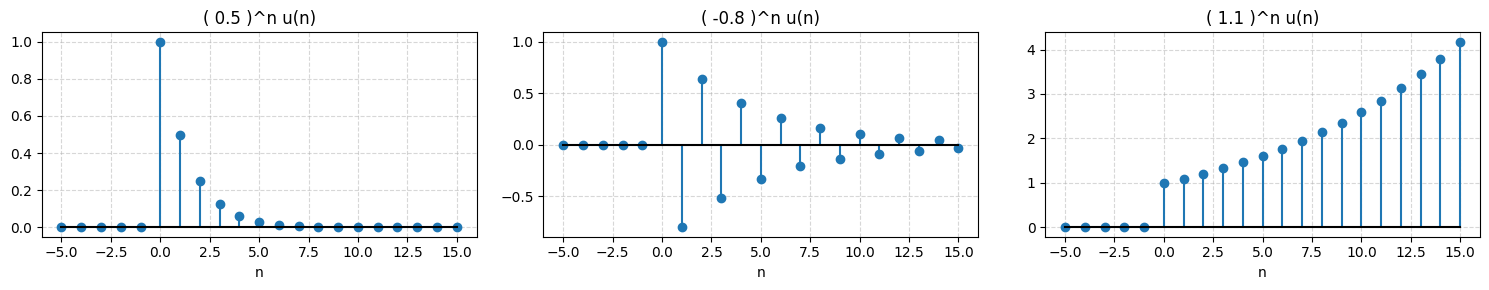

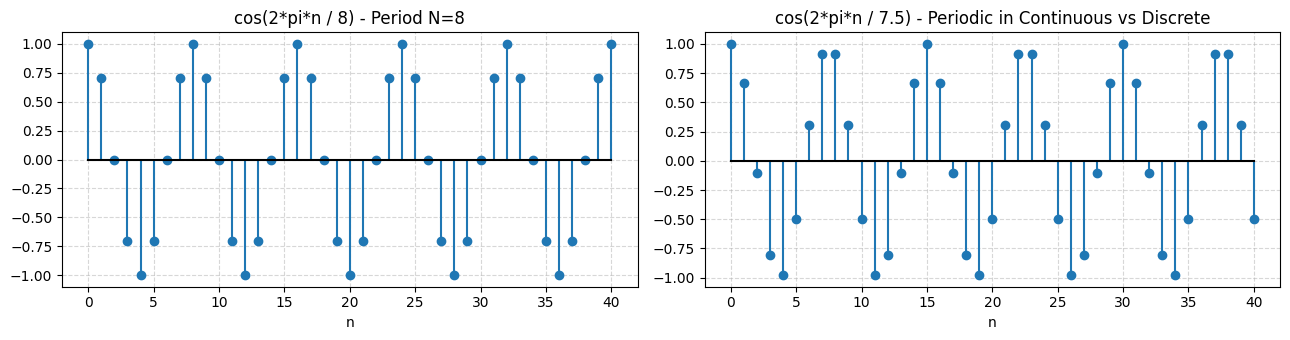

In [ ]:
# =====================================================================
# TASK 1.2: Change the Parameters
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt

# Part 1: Plot (a)^n * u(n) for different a values
n = np.arange(-5, 16)  # extended range to observe behavior
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
a_values = [0.5, -0.8, 1.1]

for ax, a in zip(axes, a_values):
    y = (a ** n.astype(float)) * step
    ax.stem(n, y, basefmt="k-")
    ax.set_title(f"( {a} )^n u(n)")
    ax.set_xlabel("n")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Part 2: Plot periodic and non-periodic cosines
n_cos = np.arange(0, 41)
cos1 = np.cos(2 * np.pi * n_cos / 8)
cos2 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

axes[0].stem(n_cos, cos1, basefmt="k-")
axes[0].set_title("cos(2*pi*n / 8) - Period N=8")
axes[0].set_xlabel("n")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].stem(n_cos, cos2, basefmt="k-")
axes[1].set_title("cos(2*pi*n / 7.5) - Periodic in Continuous vs Discrete")
axes[1].set_xlabel("n")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Audio file 'my_voice.wav' not found. Generating fallback chirp signal...


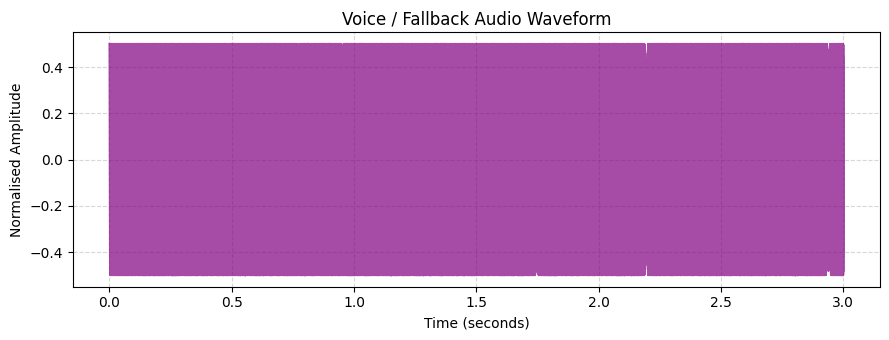

In [ ]:
# =====================================================================
# TASK 1.3: Working with Audio
# =====================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio

fname = "my_voice.wav"                      # change to your file name if different

if os.path.exists(fname):
    print(f"Loading your voice file: '{fname}'")
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                          # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))               # normalise to [-1, 1]
else:
    print("Audio file 'my_voice.wav' not found. Generating fallback chirp signal...")
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

# Plot the audio signal waveform
time_axis = np.arange(len(x)) / fs
plt.figure(figsize=(9, 3.5))
plt.plot(time_axis, x, color='purple', alpha=0.7)
plt.title("Voice / Fallback Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalised Amplitude")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Play the audio inside the notebook
Audio(x, rate=fs)